# 📊 03. Phân tích Khám phá Dữ liệu (EDA) - TFT Meta Analysis

**Thành viên thực hiện:** Thành viên 1 & Thành viên 2

Mục tiêu:
- Phân tích phân phối tỷ lệ xuất hiện (pick-rate) và tỷ lệ thắng (win-rate) của Tướng.
- Khám phá mức độ phổ biến và hiệu quả của Trang bị (Items).
- Phân tích kích hoạt Tộc/Hệ (Traits).
- So sánh đặc trưng giữa 2 nhóm Win (Top 1-4) và Lose (Top 5-8).
- Tìm kiếm các tín hiệu ban đầu về 'Hidden Meta'.

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast
import json
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

## 1. Nạp dữ liệu đã tiền xử lý

In [2]:
df = pd.read_csv('../data/processed/tft_processed.csv')
print(f'Số lượng mẫu: {len(df):,}')
df.head()

Số lượng mẫu: 399,754


,match_id,player_id,placement,tier,level,rounds_survived,game_duration_s,champions,champion_stars,items,active_traits,num_champions,num_items,num_active_traits,result
0,KR_4247538593,KR_4247538593_1,1,Challenger,8,35,2142.470703,"[""JarvanIV"", ""Sona"", ""Rakan"", ""XinZhao"", ""Neek...","{""JarvanIV"": 3, ""Sona"": 3, ""Rakan"": 3, ""XinZha...","{""JarvanIV"": [27], ""Sona"": [46], ""Rakan"": [37,...","{""DarkStar"": 2, ""Protector"": 4, ""Rebel"": 1, ""S...",8,8,7,Win
1,KR_4247538593,KR_4247538593_2,2,Challenger,9,35,2142.470703,"[""Malphite"", ""Yasuo"", ""Sona"", ""MasterYi"", ""Jin...","{""Malphite"": 2, ""Yasuo"": 2, ""Sona"": 2, ""Master...","{""Malphite"": [7], ""Yasuo"": [99, 22, 23], ""Kayl...","{""Blaster"": 2, ""Mercenary"": 1, ""Rebel"": 6, ""Se...",9,12,9,Win
2,KR_4247538593,KR_4247538593_3,3,Challenger,8,34,2142.470703,"[""KaiSa"", ""Annie"", ""Shaco"", ""Rumble"", ""Karma"",...","{""KaiSa"": 2, ""Annie"": 2, ""Shaco"": 2, ""Rumble"":...","{""KaiSa"": [99, 2, 23], ""Annie"": [37], ""Shaco"":...","{""Cybernetic"": 1, ""DarkStar"": 3, ""Demolitionis...",8,10,8,Win
3,KR_4247538593,KR_4247538593_4,4,Challenger,8,33,2142.470703,"[""KaiSa"", ""Annie"", ""Shaco"", ""Rumble"", ""Fizz"", ...","{""KaiSa"": 2, ""Annie"": 2, ""Shaco"": 2, ""Rumble"":...","{""KaiSa"": [44, 37], ""Shaco"": [15, 16, 14], ""Fi...","{""Blaster"": 1, ""Cybernetic"": 1, ""DarkStar"": 1,...",8,10,11,Win
4,KR_4247538593,KR_4247538593_5,5,Challenger,9,33,2142.470703,"[""Ziggs"", ""Yasuo"", ""Sona"", ""MasterYi"", ""Jinx"",...","{""Ziggs"": 1, ""Yasuo"": 1, ""Sona"": 1, ""MasterYi""...","{""MasterYi"": [5], ""MissFortune"": [12, 79], ""Ga...","{""Blaster"": 2, ""Demolitionist"": 2, ""Mercenary""...",9,9,10,Lose


## 2. Phân tích Tướng (Champions: Pick-rate & Win-rate)

In [3]:
def parse_list(val):
    if isinstance(val, list): return val
    if isinstance(val, str):
        if '|' in val: return val.split('|')
        try: return ast.literal_eval(val)
        except: return val.split(',')
    return []

all_records = []
for _, row in df.iterrows():
    champs = parse_list(row['champions'])
    is_win = 1 if row['result'] == 'Win' else 0
    for c in champs:
        all_records.append({'champion': c, 'is_win': is_win, 'placement': row['placement']})

champ_df = pd.DataFrame(all_records)
champ_stats = champ_df.groupby('champion').agg(
    pick_count=('is_win', 'count'),
    win_rate=('is_win', 'mean'),
    avg_placement=('placement', 'mean')
).reset_index()

champ_stats['pick_rate'] = champ_stats['pick_count'] / len(df)
champ_stats = champ_stats.sort_values(by='pick_count', ascending=False)
champ_stats.head(15)

,champion,pick_count,win_rate,avg_placement,pick_rate
93,Vi,123554,0.534430,4.320548,0.309075
7,Blitzcrank,120046,0.516985,4.412692,0.300300
31,Kassadin,108657,0.520878,4.377601,0.271810
16,Ezreal,106302,0.522502,4.380868,0.265919
56,MissFortune,105382,0.620894,3.869826,0.263617
97,WuKong,101817,0.513853,4.408232,0.254699
52,Malphite,99395,0.526928,4.366678,0.248640
11,ChoGath,94857,0.547782,4.252095,0.237288
76,Shen,91329,0.494925,4.529032,0.228463
32,Kayle,91115,0.542644,4.270065,0.227928


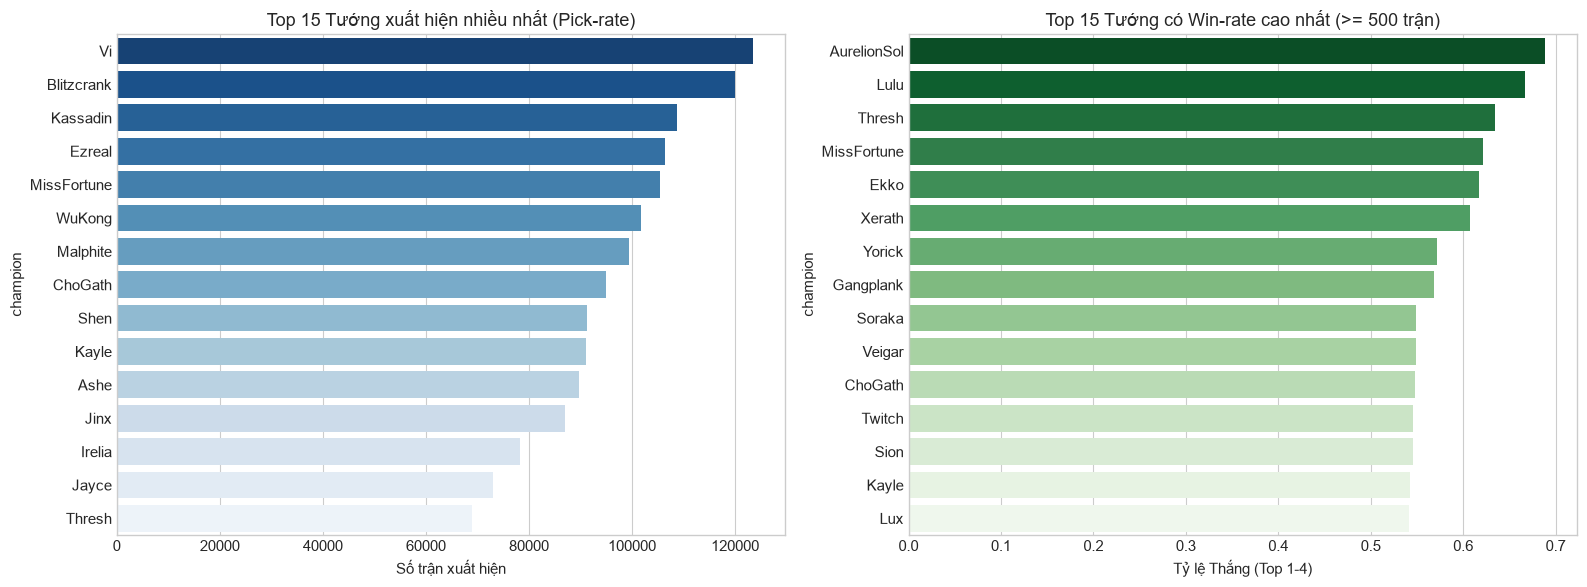

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=champ_stats.head(15), x='pick_count', y='champion', palette='Blues_r', ax=axes[0])
axes[0].set_title('Top 15 Tướng xuất hiện nhiều nhất (Pick-rate)')
axes[0].set_xlabel('Số trận xuất hiện')

top_wr = champ_stats[champ_stats['pick_count'] >= 500].sort_values(by='win_rate', ascending=False).head(15)
sns.barplot(data=top_wr, x='win_rate', y='champion', palette='Greens_r', ax=axes[1])
axes[1].set_title('Top 15 Tướng có Win-rate cao nhất (>= 500 trận)')
axes[1].set_xlabel('Tỷ lệ Thắng (Top 1-4)')

# axes[1].legend()

plt.tight_layout()
plt.show()

## 3. Bản đồ Phát hiện Hidden Meta (Pick-rate vs Win-rate Scatter)

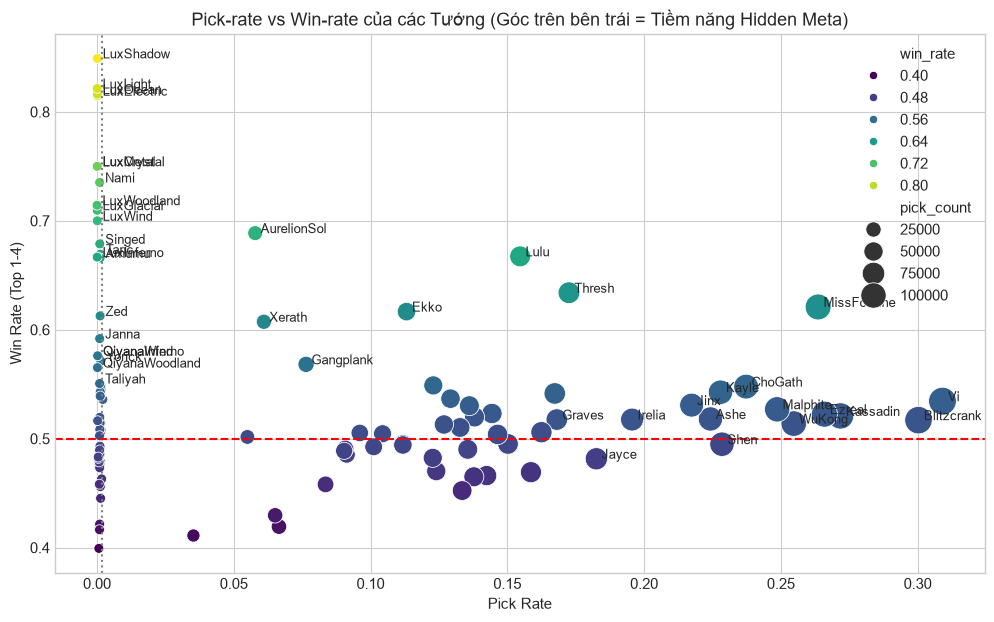

In [5]:
fig, ax = plt.subplots(figsize=(12, 7))
sns.scatterplot(data=champ_stats, x='pick_rate', y='win_rate', size='pick_count', sizes=(50, 400), hue='win_rate', palette='viridis', ax=ax)

median_pick = champ_stats['pick_rate'].median()
ax.axvline(median_pick, color='gray', linestyle=':')
ax.axhline(0.5, color='red', linestyle='--')

for _, row in champ_stats.iterrows():
    # Nhãn các tướng có Winrate cao nhưng pick thấp (Góc trên bên trái: Hidden Meta)
    if row['win_rate'] > 0.55 or row['pick_rate'] > champ_stats['pick_rate'].quantile(0.85):
        ax.text(row['pick_rate'] + 0.002, row['win_rate'], row['champion'], fontsize=9)

ax.set_title('Pick-rate vs Win-rate của các Tướng (Góc trên bên trái = Tiềm năng Hidden Meta)')
ax.set_xlabel('Pick Rate')
ax.set_ylabel('Win Rate (Top 1-4)')
plt.show()

## 4. Phân tích Trang bị (Items)

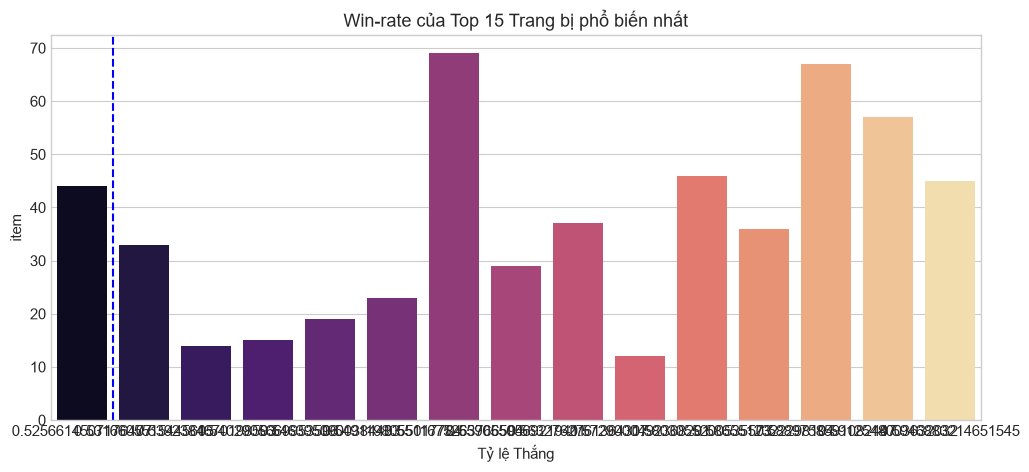

In [6]:
def parse_dict(val):
    if isinstance(val, dict): return val
    try: return json.loads(val)
    except: return {}

item_records = []
for _, row in df.iterrows():
    items_dict = parse_dict(row['items'])
    is_win = 1 if row['result'] == 'Win' else 0
    for champ, itms in items_dict.items():
        for item in itms:
            item_records.append({'item': item, 'champion': champ, 'is_win': is_win})

item_df = pd.DataFrame(item_records)
item_stats = item_df.groupby('item').agg(
    count=('is_win', 'count'),
    win_rate=('is_win', 'mean')
).reset_index().sort_values(by='count', ascending=False)

plt.figure(figsize=(12, 5))
sns.barplot(data=item_stats.head(15), x='win_rate', y='item', palette='magma')
plt.axvline(0.5, color='blue', linestyle='--')
plt.title('Win-rate của Top 15 Trang bị phổ biến nhất')
plt.xlabel('Tỷ lệ Thắng')
plt.show()

## 5. Kết luận sơ bộ từ EDA
- Dữ liệu có sự phân hóa rõ ràng về Win-rate giữa các nhóm Tướng.
- Xuất hiện một số tướng có tỷ lệ xuất hiện không quá cao nhưng win-rate vượt trội >55% (ứng viên cho Hidden Meta).
- Trang bị sát thương/chủ lực (IE, Jeweled Gauntlet, Rageblade) có tác động mạnh mẽ đến thứ hạng cuối trận.